# Lab Assignment 13

**Prerequisite:** the class demo notebook *ICL_and_Instruction_Finetuning_Demo.ipynb*  
**Runtime:** Google Colab with a T4 GPU (about 10–15 minutes of GPU time per task)

Each task is a small, real NLP problem: you design the solution, run the experiments and explain what you found. Only data loading and evaluation functions are given, so that everyone's numbers are comparable.

## Rules
- Use only the models named in each task.
- You may reuse any code from the class demo. Cite any other source.
- Fix random seeds and report the settings you used.
- The two tasks are independent, so you can restart the runtime between them.

## Submission
Submit this notebook as `.ipynb` **with all outputs visible**.

## 0. Setup

In [1]:
!pip install -q transformers datasets accelerate sentence-transformers scikit-learn

In [2]:
import re, time, random, gc, sqlite3, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq,
                          Trainer, TrainingArguments)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 300)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_causal_lm(name):
    """Load a decoder-only model in fp32 (numerically safe on a T4) and its tokenizer."""
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(name).to(device).eval()
    return tok, model


@torch.no_grad()
def generate_batch(model, tok, prompts, max_new_tokens=64, batch_size=8, stop_strings=None, desc="generating"):
    """Greedy, batched generation. Returns only the new text for each prompt, cut at the first stop string."""
    kwargs = dict(stop_strings=stop_strings, tokenizer=tok) if stop_strings else {}
    old_side, tok.padding_side = tok.padding_side, "left"
    outputs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, **kwargs)
        for row in gen[:, enc["input_ids"].shape[1]:]:
            text = tok.decode(row, skip_special_tokens=True)
            for s in (stop_strings or []):
                text = text.split(s)[0]
            outputs.append(text.strip())
    tok.padding_side = old_side
    return outputs

Device: cuda


---
# Section A: In-Context Learning

## Task 1. A news-topic classifier with zero training (50 marks)

**Scenario.** A news website wants to tag articles as **World**, **Sports**, **Business** or **Sci/Tech**. It has only 200 labelled articles and no budget to train a model. Build the best classifier you can using **only in-context learning**, then decide whether it is actually a better choice than a simple classical model.

**Constraints**
- Model: `Qwen/Qwen2.5-0.5B` (base). No weight updates.
- Demonstrations may only come from `ag_pool`, with **at most 8 per prompt**.
- Every prediction must be one of the four classes. Report final numbers on `ag_test` using `report_classification`.

**What you must do**
1. **Baselines.** Evaluate zero-shot and 8 randomly chosen demonstrations.
2. **Retrieval-based demonstrations.** For each test article, choose the 8 most similar articles from `ag_pool` as demonstrations, using sentence embeddings from `sentence-transformers/all-MiniLM-L6-v2`. Compare with random selection.
3. **Classical baseline.** Train TF-IDF + logistic regression on the same 200 articles.
4. **Error analysis.** Show the confusion matrix of your best system and explain 3 of its mistakes.

**Analysis questions** (about 250 words in total)
- (a) Did retrieval-based demonstrations beat random ones? Why do you think similar examples help?
- (b) Which classes get confused most often, and why might that be?
- (c) Compare your best ICL system with logistic regression on accuracy **and** speed (seconds per article). Which would you deploy for this website, and why?



In [3]:
ag = load_dataset("fancyzhx/ag_news")
AG_LABELS = ["World", "Sports", "Business", "Sci/Tech"]

ag_test = ag["test"].shuffle(seed=0).select(range(200))
_train = ag["train"].shuffle(seed=1)
ag_pool = _train.select(range(200))          # the ONLY labelled data you may use
ag_dev = _train.select(range(200, 300))      # use for design decisions (prompt format, label words)

for name, ds in [("pool", ag_pool), ("dev", ag_dev), ("test", ag_test)]:
    counts = Counter(ds["label"])
    print(f"{name:5s}", {AG_LABELS[k]: counts[k] for k in range(4)})
print("\nExample:", ag_pool[0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

pool  {'World': 48, 'Sports': 53, 'Business': 49, 'Sci/Tech': 50}
dev   {'World': 23, 'Sports': 26, 'Business': 33, 'Sci/Tech': 18}
test  {'World': 49, 'Sports': 47, 'Business': 50, 'Sci/Tech': 54}

Example: {'text': "Brown feels fortunate to have a hand in series Thirty-two pitches. That's a couple innings for most pitchers -- or two lengthy Johnny Damon at-bats. It amounted to Kevin Brown's entire body of work against the Red Sox Sept. 26. It was not a pretty sight.", 'label': 1}


In [4]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

RESULTS_T1 = []   # append the dict returned by report_classification for every system


def report_classification(y_true, y_pred, method, sec_per_example=None, show_cm=False):
    """Fixed evaluation for Task 1. y_true / y_pred are lists of label ids (0-3)."""
    res = {"method": method,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro"),
           "sec_per_example": sec_per_example}
    if show_cm:
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(4)), display_labels=AG_LABELS,
                                                cmap="Blues", xticks_rotation=45)
        plt.title(method); plt.show()
    return res

### Task 1: Your solution
Add as many code and text cells as you need.

### Design

**How a prediction is made.** The model never generates free text. Each article becomes a prompt that ends in `Topic:`. One forward pass gives the next-token distribution, and I compare the log-probabilities of the **four label words only** (verbaliser scoring, the same idea as `word_logprob` in the class demo). The arg-max is always one of the four classes, so the "valid class" constraint holds by construction, and the four scores double as a confidence.

**Pipeline**
1. Clean the AG News text, which contains HTML debris (`#39;` for an apostrophe, `quot;`, `&lt;b&gt;` tags, backslashes).
2. Make every design decision on `ag_dev`, never on `ag_test`: the label words (`Sci/Tech` vs `Technology`), whether to add an instruction line, the order of retrieved demonstrations, and whether to use *contextual calibration* (Zhao et al., 2021, *Calibrate Before Use*). Calibration scores the content-free input `"N/A"` with the same demonstrations and divides those probabilities out, which removes the prompt's built-in bias towards some labels.
3. Test on `ag_test`:
   - zero-shot;
   - 8 random demonstrations, repeated with 3 seeds because random-demonstration ICL has high variance;
   - 8 retrieved demonstrations: the nearest `ag_pool` neighbours under `all-MiniLM-L6-v2` cosine similarity.
4. Classical models trained on the same 200 articles: TF-IDF + logistic regression (required), plus two cheap references that help the analysis. The first is a MiniLM *k*-NN vote, which uses the retrieved labels without any LM. The second is logistic regression on MiniLM embeddings.
5. Error analysis of the best system.

**Speed** is wall-clock seconds per test article on the Colab T4, with articles processed one at a time (batch size 1, fp32). This mimics a website tagging articles as they arrive. The retrieval system's time includes embedding the query. Total GPU time for this task is about 6–8 minutes.

In [5]:
# ---------- Task 1: settings (all fixed and reported at the end) ----------
import html
from sentence_transformers import SentenceTransformer
from sklearn.metrics import confusion_matrix

SEED = 0
ICL_MODEL = "Qwen/Qwen2.5-0.5B"
EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
K_SHOTS = 8                  # maximum allowed demonstrations per prompt
RANDOM_SEEDS = [0, 1, 2]     # three draws of random demonstrations
MAX_WORDS = 80               # each article is cut to this many words inside a prompt
set_seed(SEED)


def clean(text):
    """AG News contains HTML debris: '#39;' for an apostrophe, 'quot;', '&lt;b&gt;' tags and backslashes."""
    text = html.unescape(text)
    text = re.sub(r"\s?&?#39;", "'", text)
    text = re.sub(r"&?quot;", '"', text)
    text = re.sub(r"&?#(\d+);", lambda m: chr(int(m.group(1))), text)
    text = re.sub(r"<[^>]*>", " ", text)
    text = text.replace("\\", " ")
    return re.sub(r"\s+", " ", text).strip()


def truncate(text, max_words=MAX_WORDS):
    words = text.split()
    return " ".join(words[:max_words]) + (" ..." if len(words) > max_words else "")


pool_texts, pool_labels = [clean(t) for t in ag_pool["text"]], np.array(list(ag_pool["label"]))
dev_texts, y_dev = [clean(t) for t in ag_dev["text"]], list(ag_dev["label"])
test_texts, y_test = [clean(t) for t in ag_test["text"]], list(ag_test["label"])

i = next((i for i, t in enumerate(ag_pool["text"]) if "#39;" in t or "\\" in t), 0)
print("raw    :", ag_pool[i]["text"])
print("cleaned:", pool_texts[i])
n_words = [len(t.split()) for t in pool_texts]
print(f"\nwords per pool article: median {np.median(n_words):.0f}, max {max(n_words)}")

raw    : Security Council agrees on Sudan resolution as foes pledge &lt;b&gt;...&lt;/b&gt; NAIROBI (AFP) - UN ambassadors agreed here unanimously on the text of a resolution aimed at restoring peace to war-ravaged Sudan, as the country #39;s main foes promised to conclude talks on their 21-year-old conflict by the end of the year.
cleaned: Security Council agrees on Sudan resolution as foes pledge ... NAIROBI (AFP) - UN ambassadors agreed here unanimously on the text of a resolution aimed at restoring peace to war-ravaged Sudan, as the country's main foes promised to conclude talks on their 21-year-old conflict by the end of the year.

words per pool article: median 38, max 74


In [6]:
# ---------- Models, label words, prompt builder and scorer ----------
tok_icl, model_icl = load_causal_lm(ICL_MODEL)
embedder = SentenceTransformer(EMB_MODEL, device=device)

# Two candidate sets of label words ("verbalisers"); the choice is made on ag_dev.
VERBALIZERS = {
    "dataset names": ["World", "Sports", "Business", "Sci/Tech"],
    "plain words": ["World", "Sports", "Business", "Technology"],
}


def label_token_ids(words):
    """The prompt ends with 'Topic:', so each label is scored by the first token of ' <word>'."""
    first = [tok_icl(" " + w, add_special_tokens=False).input_ids[0] for w in words]
    assert len(set(first)) == len(words), f"label words must start with different tokens: {words}"
    return first


for name, words in VERBALIZERS.items():
    print(f"{name:14s}", {w: tok_icl.tokenize(" " + w) for w in words})


def build_prompt(text, demo_idx, words, instruction=True):
    """demo_idx: indices into ag_pool, in the order they should appear in the prompt."""
    head = f"Classify each news article as {', '.join(words[:-1])} or {words[-1]}.\n\n" if instruction else ""
    shots = "".join(f"Article: {truncate(pool_texts[j])}\nTopic: {words[pool_labels[j]]}\n\n" for j in demo_idx)
    return head + shots + f"Article: {truncate(text)}\nTopic:"


def timer():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def softmax(x):
    z = np.exp(x - x.max(axis=1, keepdims=True))
    return z / z.sum(axis=1, keepdims=True)


@torch.no_grad()
def label_logprobs(prompts, label_ids, desc="scoring"):
    """One forward pass per prompt (batch size 1, so no padding). Returns an (n, 4) array of
    log P(label | prompt), renormalised over the four label tokens."""
    body, lm_head = model_icl.base_model, model_icl.get_output_embeddings()
    idx = torch.tensor(label_ids, device=device)
    out = np.zeros((len(prompts), len(label_ids)), dtype=np.float32)
    for n, p in enumerate(tqdm(prompts, desc=desc, leave=False)):
        ids = tok_icl(p, return_tensors="pt").input_ids.to(device)
        h_last = body(input_ids=ids, use_cache=False).last_hidden_state[:, -1]   # only the next-token position matters
        out[n] = torch.log_softmax(lm_head(h_last)[0, idx].float(), dim=-1).cpu().numpy()
    return out


def run_icl(texts, demo_fn, words, instruction=True, desc="ICL"):
    """demo_fn(i) -> list of ag_pool indices used as demonstrations for article i.
    Returns raw and contextually calibrated predictions, each with its seconds per article."""
    label_ids = label_token_ids(words)
    demos = [[int(j) for j in demo_fn(i)] for i in range(len(texts))]
    prompts = [build_prompt(t, d, words, instruction) for t, d in zip(texts, demos)]

    t0 = timer()
    logp = label_logprobs(prompts, label_ids, desc)
    t_raw = timer() - t0

    # Contextual calibration: same demonstrations, content-free article "N/A"; its label distribution is divided out.
    t0 = timer()
    keys = [tuple(d) for d in demos]
    uniq = list(dict.fromkeys(keys))            # fixed demonstrations -> a single extra forward pass
    cf = label_logprobs([build_prompt("N/A", list(k), words, instruction) for k in uniq], label_ids, desc + " [calib]")
    cf_of = dict(zip(uniq, cf))
    logp_cal = logp - np.stack([cf_of[k] for k in keys])
    t_cal = timer() - t0

    n = len(texts)
    return {"pred": logp.argmax(1), "proba": np.exp(logp), "sec": t_raw / n,
            "pred_cal": logp_cal.argmax(1), "proba_cal": softmax(logp_cal), "sec_cal": (t_raw + t_cal) / n,
            "demos": demos, "prompts": prompts}


# ---------- Demonstration selectors ----------
def zero_shot(i):
    return []


def random_selector(seed, k=K_SHOTS):
    """The same k random pool articles for every test article."""
    idx = np.random.RandomState(seed).choice(len(pool_texts), k, replace=False).tolist()
    return lambda i: idx


def embed(texts):
    return embedder.encode(texts, batch_size=64, normalize_embeddings=True, convert_to_numpy=True,
                           show_progress_bar=False)


def nearest_pool(query_emb, k=K_SHOTS):
    """Indices and cosine similarities of the k most similar pool articles, most similar first."""
    sims = query_emb @ pool_emb.T
    top = np.argsort(-sims, axis=1)[:, :k]
    return top, np.take_along_axis(sims, top, axis=1)


def knn_selector(query_emb, k=K_SHOTS, most_similar_last=True):
    top, _ = nearest_pool(query_emb, k)
    if most_similar_last:                       # the closest example sits right before the query
        top = top[:, ::-1]
    return lambda i: top[i].tolist()


pool_emb = embed(pool_texts)
dev_emb = embed(dev_texts)
t0 = timer()
test_emb = embed(test_texts)
EMB_SEC = (timer() - t0) / len(test_texts)
print(f"\nMiniLM embedding cost: {EMB_SEC * 1000:.2f} ms per article")

example = build_prompt(test_texts[0], knn_selector(test_emb)(0), VERBALIZERS["plain words"])
print(f"\nExample 8-shot retrieval prompt ({len(tok_icl(example).input_ids)} tokens):\n")
print(example)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

... (13 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

dataset names  {'World': ['ĠWorld'], 'Sports': ['ĠSports'], 'Business': ['ĠBusiness'], 'Sci/Tech': ['ĠSci', '/T', 'ech']}
plain words    {'World': ['ĠWorld'], 'Sports': ['ĠSports'], 'Business': ['ĠBusiness'], 'Technology': ['ĠTechnology']}

MiniLM embedding cost: 1.15 ms per article

Example 8-shot retrieval prompt (530 tokens):

Classify each news article as World, Sports, Business or Technology.

Article: Limit sweet deals for Fannie Mae Accounting scandals, first at Freddie Mac and now alleged at Fannie Mae, call into question the future of those government-sponsored but investor-owned companies that buy home mortgages from lenders.
Topic: Business

Article: Rookie J. Jones, Cowboys Up and Running NFL scouts and front-office executives were less than enamored of the top tailbacks available in the draft in April. The first didn't come off the board until the St.
Topic: Sports

Article: Royalty payout could await voices behind 'The Wall' (AFP) AFP - The youngsters who sang the chorus 

In [7]:
# ---------- Design decisions on ag_dev (100 articles); ag_test is not touched here ----------
dev_rows = []
for vname, words in VERBALIZERS.items():
    for instruction in (False, True):
        for shots, selector in [("0-shot", zero_shot), ("random 8-shot", random_selector(SEED))]:
            r = run_icl(dev_texts, selector, words, instruction, desc=f"dev | {vname} | instr={instruction} | {shots}")
            dev_rows.append({"label words": vname, "instruction": instruction, "demos": shots,
                             "acc": accuracy_score(y_dev, r["pred"]),
                             "acc (calibrated)": accuracy_score(y_dev, r["pred_cal"])})
dev_df = pd.DataFrame(dev_rows)
display(dev_df.round(3))

# Prompt format = best mean dev accuracy over its 4 numbers (0-shot / 8-shot x raw / calibrated)
fmt_score = dev_df.groupby(["label words", "instruction"])[["acc", "acc (calibrated)"]].mean().mean(axis=1)
WORDS_NAME, INSTRUCTION = fmt_score.idxmax()
WORDS, INSTRUCTION = VERBALIZERS[WORDS_NAME], bool(INSTRUCTION)
print(f"Chosen prompt format: label words = {WORDS} | instruction line = {INSTRUCTION}")

dev | dataset names | instr=False | 0-shot:   0%|          | 0/100 [00:00<?, ?it/s]

dev | dataset names | instr=False | 0-shot [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

dev | dataset names | instr=False | random 8-shot:   0%|          | 0/100 [00:00<?, ?it/s]

dev | dataset names | instr=False | random 8-shot [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

dev | dataset names | instr=True | 0-shot:   0%|          | 0/100 [00:00<?, ?it/s]

dev | dataset names | instr=True | 0-shot [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

dev | plain words | instr=True | random 8-shot:   0%|          | 0/100 [00:00<?, ?it/s]

dev | plain words | instr=True | random 8-shot [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

,label words,instruction,demos,acc,acc (calibrated)
0,dataset names,False,0-shot,0.76,0.78
1,dataset names,False,random 8-shot,0.76,0.78
2,dataset names,True,0-shot,0.68,0.65
3,dataset names,True,random 8-shot,0.73,0.79
4,plain words,False,0-shot,0.83,0.85
5,plain words,False,random 8-shot,0.77,0.78
6,plain words,True,0-shot,0.75,0.63
7,plain words,True,random 8-shot,0.75,0.82


Chosen prompt format: label words = ['World', 'Sports', 'Business', 'Technology'] | instruction line = False


In [8]:
# ---------- Design decision on ag_dev: order of the retrieved demonstrations ----------
knn_dev_rows = []
for last in (True, False):
    r = run_icl(dev_texts, knn_selector(dev_emb, most_similar_last=last), WORDS, INSTRUCTION,
                desc=f"dev | retrieval | most similar {'last' if last else 'first'}")
    knn_dev_rows.append({"order": "most similar last" if last else "most similar first", "most_similar_last": last,
                         "acc": accuracy_score(y_dev, r["pred"]),
                         "acc (calibrated)": accuracy_score(y_dev, r["pred_cal"])})
knn_dev = pd.DataFrame(knn_dev_rows)
display(knn_dev.drop(columns="most_similar_last").round(3))
KNN_LAST = bool(knn_dev.loc[knn_dev[["acc", "acc (calibrated)"]].max(axis=1).idxmax(), "most_similar_last"])
print("Chosen order for retrieved demonstrations:", "most similar last" if KNN_LAST else "most similar first")

dev | retrieval | most similar last:   0%|          | 0/100 [00:00<?, ?it/s]

dev | retrieval | most similar last [calib]:   0%|          | 0/100 [00:00<?, ?it/s]

dev | retrieval | most similar first:   0%|          | 0/100 [00:00<?, ?it/s]

dev | retrieval | most similar first [calib]:   0%|          | 0/100 [00:00<?, ?it/s]

,order,acc,acc (calibrated)
0,most similar last,0.89,0.81
1,most similar first,0.87,0.80


Chosen order for retrieved demonstrations: most similar last


In [9]:
# ---------- Final ICL evaluation on ag_test ----------
PREDS_T1, PROBA_T1, RUNS_T1 = {}, {}, {}


def record(method, pred, sec, proba=None):
    """Evaluate with the fixed report_classification and store (re-running a cell replaces the old row)."""
    RESULTS_T1[:] = [r for r in RESULTS_T1 if r["method"] != method]
    RESULTS_T1.append(report_classification(y_test, [int(p) for p in pred], method, sec_per_example=sec))
    PREDS_T1[method], PROBA_T1[method] = np.asarray(pred), proba
    print(f"{method:42s} acc={RESULTS_T1[-1]['accuracy']:.3f}  macro-F1={RESULTS_T1[-1]['macro_f1']:.3f}  "
          f"sec/article={sec:.4f}")


set_seed(SEED)
r = RUNS_T1["zero"] = run_icl(test_texts, zero_shot, WORDS, INSTRUCTION, desc="test | 0-shot")
record("ICL 0-shot", r["pred"], r["sec"], r["proba"])
record("ICL 0-shot + calibration", r["pred_cal"], r["sec_cal"], r["proba_cal"])

for s in RANDOM_SEEDS:
    r = RUNS_T1[f"random{s}"] = run_icl(test_texts, random_selector(s), WORDS, INSTRUCTION,
                                        desc=f"test | random 8-shot seed {s}")
    record(f"ICL random 8-shot (seed {s})", r["pred"], r["sec"], r["proba"])
    record(f"ICL random 8-shot (seed {s}) + calibration", r["pred_cal"], r["sec_cal"], r["proba_cal"])

r = RUNS_T1["knn"] = run_icl(test_texts, knn_selector(test_emb, most_similar_last=KNN_LAST), WORDS, INSTRUCTION,
                             desc="test | retrieval 8-shot")
record("ICL retrieval 8-shot", r["pred"], r["sec"] + EMB_SEC, r["proba"])
record("ICL retrieval 8-shot + calibration", r["pred_cal"], r["sec_cal"] + EMB_SEC, r["proba_cal"])

test | 0-shot:   0%|          | 0/200 [00:00<?, ?it/s]

test | 0-shot [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

ICL 0-shot                                 acc=0.750  macro-F1=0.750  sec/article=0.0456
ICL 0-shot + calibration                   acc=0.750  macro-F1=0.757  sec/article=0.0459


test | random 8-shot seed 0:   0%|          | 0/200 [00:00<?, ?it/s]

test | random 8-shot seed 0 [calib]:   0%|          | 0/1 [00:00<?, ?it/s]

ICL random 8-shot (seed 0)                 acc=0.650  macro-F1=0.594  sec/article=0.1904
ICL random 8-shot (seed 0) + calibration   acc=0.800  macro-F1=0.794  sec/article=0.1913


... (5 outputs left out)

ICL random 8-shot (seed 2)                 acc=0.730  macro-F1=0.729  sec/article=0.1907
ICL random 8-shot (seed 2) + calibration   acc=0.830  macro-F1=0.823  sec/article=0.1916


test | retrieval 8-shot:   0%|          | 0/200 [00:00<?, ?it/s]

test | retrieval 8-shot [calib]:   0%|          | 0/200 [00:00<?, ?it/s]

ICL retrieval 8-shot                       acc=0.870  macro-F1=0.872  sec/article=0.1985
ICL retrieval 8-shot + calibration         acc=0.765  macro-F1=0.764  sec/article=0.3767


In [10]:
# ---------- Classical baselines, trained on the same 200 pool articles ----------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline


def make_tfidf_lr(ngram, C):
    return make_pipeline(TfidfVectorizer(ngram_range=ngram, sublinear_tf=True, stop_words="english"),
                         LogisticRegression(C=C, max_iter=5000, random_state=SEED))


def per_article_seconds(predict_one, items):
    """Wall-clock seconds per article when articles arrive one at a time (as on a website)."""
    t0 = time.perf_counter()
    for x in items:
        predict_one(x)
    return (time.perf_counter() - t0) / len(items)


# 1) TF-IDF + logistic regression; hyper-parameters chosen on ag_dev, like the ICL design choices
grid = [{"ngram": ng, "C": C,
         "dev acc": accuracy_score(y_dev, make_tfidf_lr(ng, C).fit(pool_texts, pool_labels).predict(dev_texts))}
        for ng in [(1, 1), (1, 2)] for C in [1, 10, 100]]
display(pd.DataFrame(grid))
best_lr = max(grid, key=lambda g: g["dev acc"])
tfidf_lr = make_tfidf_lr(best_lr["ngram"], best_lr["C"])
t0 = time.perf_counter()
tfidf_lr.fit(pool_texts, pool_labels)
LR_FIT_SEC = time.perf_counter() - t0
sec = per_article_seconds(lambda t: tfidf_lr.predict([t]), test_texts)
record("TF-IDF + LogReg", tfidf_lr.predict(test_texts), sec, tfidf_lr.predict_proba(test_texts))
print(f"   (ngram={best_lr['ngram']}, C={best_lr['C']}; training took {LR_FIT_SEC:.2f} s on CPU)")


# 2) Reference: similarity-weighted vote of the same 8 MiniLM neighbours the retrieval prompts use (no LM at all)
def knn_vote_proba(query_emb, k=K_SHOTS):
    top, sims = nearest_pool(query_emb, k)
    sims = np.clip(sims, 1e-6, None)
    votes = np.stack([np.where(pool_labels[top] == c, sims, 0).sum(1) for c in range(4)], axis=1)
    return votes / votes.sum(1, keepdims=True)


t0 = time.perf_counter()
vote = knn_vote_proba(test_emb)
vote_sec = (time.perf_counter() - t0) / len(test_texts)
record("kNN vote (MiniLM, k=8, no LM)", vote.argmax(1), EMB_SEC + vote_sec, vote)

# 3) Reference: logistic regression on MiniLM sentence embeddings
grid_emb = [{"C": C, "dev acc": accuracy_score(
                 y_dev, LogisticRegression(C=C, max_iter=5000).fit(pool_emb, pool_labels).predict(dev_emb))}
            for C in [0.1, 1, 10, 100]]
best_C = max(grid_emb, key=lambda g: g["dev acc"])["C"]
emb_lr = LogisticRegression(C=best_C, max_iter=5000, random_state=SEED).fit(pool_emb, pool_labels)
sec = EMB_SEC + per_article_seconds(lambda e: emb_lr.predict(e[None]), test_emb)
record("MiniLM embeddings + LogReg", emb_lr.predict(test_emb), sec, emb_lr.predict_proba(test_emb))
print(f"   (C={best_C})")

,ngram,C,dev acc
0,"(1, 1)",1,0.74
1,"(1, 1)",10,0.74
2,"(1, 1)",100,0.74
3,"(1, 2)",1,0.73
4,"(1, 2)",10,0.74
5,"(1, 2)",100,0.73


TF-IDF + LogReg                            acc=0.715  macro-F1=0.713  sec/article=0.0012
   (ngram=(1, 1), C=1; training took 0.11 s on CPU)
kNN vote (MiniLM, k=8, no LM)              acc=0.845  macro-F1=0.847  sec/article=0.0012
MiniLM embeddings + LogReg                 acc=0.875  macro-F1=0.877  sec/article=0.0013
   (C=10)


,method,accuracy,macro_f1,sec_per_example
0,MiniLM embeddings + LogReg,0.875,0.8769,0.0013
1,ICL retrieval 8-shot,0.870,0.8718,0.1985
2,"kNN vote (MiniLM, k=8, no LM)",0.845,0.8469,0.0012
3,ICL random 8-shot (seed 2) + calibration,0.830,0.8231,0.1916
4,ICL random 8-shot (seed 1),0.825,0.8216,0.2022
5,ICL random 8-shot (seed 0) + calibration,0.800,0.7944,0.1913
6,ICL random 8-shot (seed 1) + calibration,0.795,0.7905,0.2032
7,ICL retrieval 8-shot + calibration,0.765,0.7644,0.3767
8,ICL 0-shot,0.750,0.7503,0.0456
9,ICL 0-shot + calibration,0.750,0.7568,0.0459


Random 8-shot: accuracy 0.735 ± 0.072 (mean ± std over seeds [0, 1, 2])
Random 8-shot + calibration: accuracy 0.808 ± 0.015 (mean ± std over seeds [0, 1, 2])


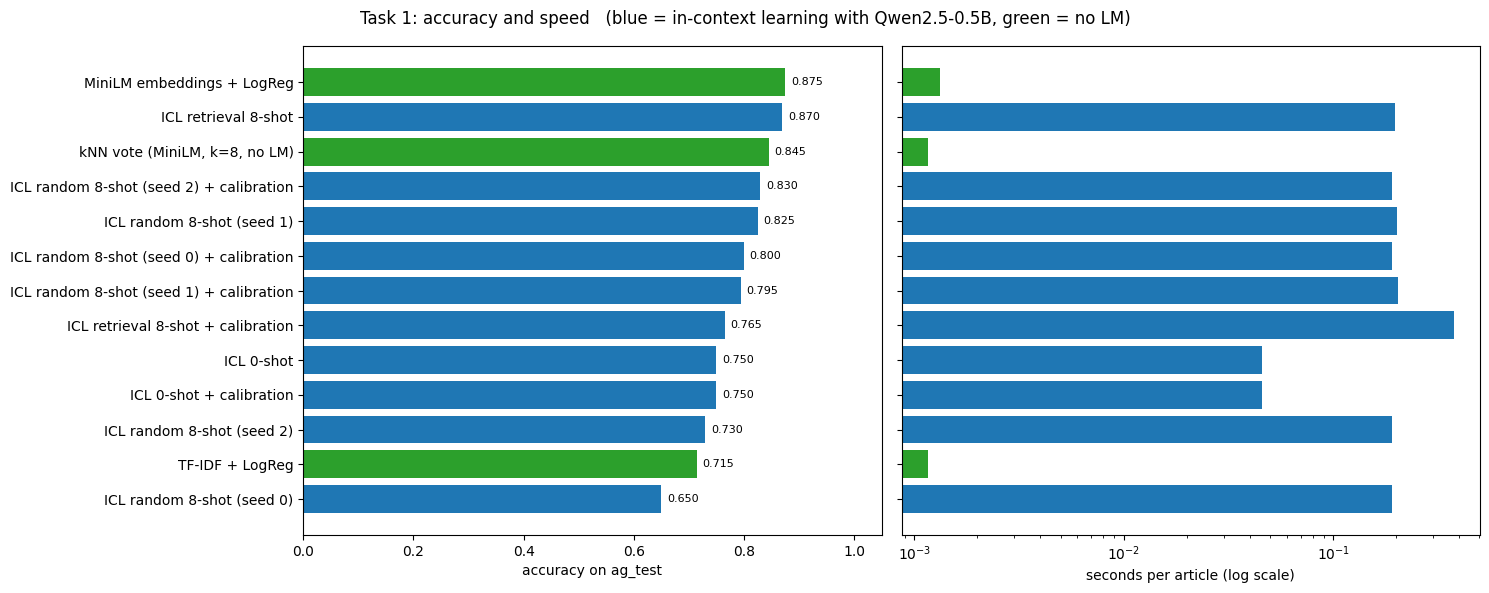

In [11]:
# ---------- Results table and plots ----------
res_t1 = pd.DataFrame(RESULTS_T1).sort_values("accuracy", ascending=False).reset_index(drop=True)
display(res_t1.round(4))

for suffix in ["", " + calibration"]:
    accs = [next(r["accuracy"] for r in RESULTS_T1 if r["method"] == f"ICL random 8-shot (seed {s}){suffix}")
            for s in RANDOM_SEEDS]
    print(f"Random 8-shot{suffix}: accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f} "
          f"(mean ± std over seeds {RANDOM_SEEDS})")

order = res_t1.iloc[::-1]
colors = ["tab:blue" if m.startswith("ICL") else "tab:green" for m in order["method"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
axes[0].barh(order["method"], order["accuracy"], color=colors)
axes[0].set_xlim(0, 1.05); axes[0].set_xlabel("accuracy on ag_test")
for y, v in enumerate(order["accuracy"]):
    axes[0].text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=8)
axes[1].barh(order["method"], order["sec_per_example"], color=colors)
axes[1].set_xscale("log"); axes[1].set_xlabel("seconds per article (log scale)")
fig.suptitle("Task 1: accuracy and speed   (blue = in-context learning with Qwen2.5-0.5B, green = no LM)")
plt.tight_layout(); plt.show()

Best system: MiniLM embeddings + LogReg  (accuracy 0.875, macro-F1 0.877)


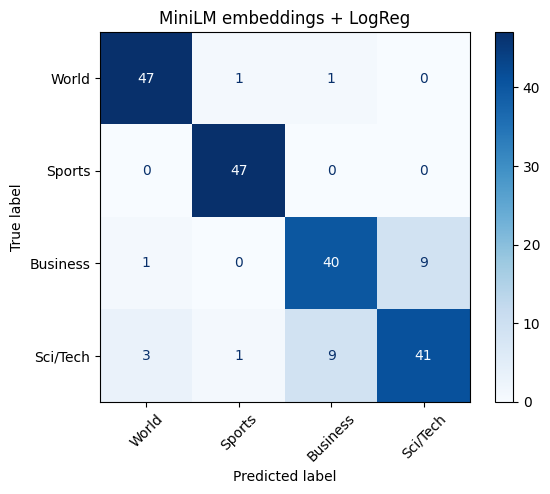

Per-class recall: {'World': np.float64(0.959), 'Sports': np.float64(1.0), 'Business': np.float64(0.8), 'Sci/Tech': np.float64(0.759)}
Most frequent confusions (gold -> predicted):
   Sci/Tech  -> Business : 9
   Business  -> Sci/Tech : 9
   Sci/Tech  -> World    : 3
   Sci/Tech  -> Sports   : 1
   Business  -> World    : 1

25 mistakes in total; a random sample of 10:


,id,gold,predicted,confidence,labels of 8 nearest pool articles,article
0,11,Sci/Tech,Business,0.52,"Business x4, World x2, Sci/Tech x2","Intel silent on Jayhawk replacement SAN FRANCISCO -- Intel Corp. on Tuesday provided a few more details about future plans for its enterprise server processors, but the company maintained its silence on its plans for an upcoming dual-core Xeon processor, which it has promised as the next major f..."
1,32,Sci/Tech,Business,0.54,"Business x4, Sci/Tech x2, World x1, Sports x1",DOJ won't appeal Oracle ruling WASHINGTON - The U.S. Department of Justice (DOJ) will not appeal a ruling by a California judge that would allow Oracle Corp.'s proposed hostile takeover of competing software vendor PeopleSoft Inc.
2,73,Business,Sci/Tech,0.54,"Sci/Tech x4, Business x3, World x1","Cisco's Q1 Profit Leaps 29 Percent Cisco Systems has reported first-quarter profits of $1.4 on sales of $6 billion. Despite cautious spending by its corporate customers, softness in the global economy and a lingering uncertainty over whether"
3,111,Business,Sci/Tech,0.78,"Sci/Tech x6, Business x2",US Bells Do Video on Path Blazed by Small Telcos The three largest US local telephone corporations made a splash this summer with plans to sell video services on their voice and data lines in a few years.
4,123,World,Sports,0.49,"World x5, Sci/Tech x1, Sports x1, Business x1","Vote 2004 - a guide to the primary Get ready for the primary with the Herald-Tribunes special news section profiling all the federal, state and local candidates in races in Tuesdays election."
5,132,Sci/Tech,Business,0.84,"Business x5, Sci/Tech x3","Dell cuts prices on many corporate products Dell on Monday said it had cut prices by as much as fifth for a range of products aimed at US corporate customers, as the computer maker passed along savings from cheaper components."
6,145,Business,Sci/Tech,0.55,"Sci/Tech x4, Business x3, World x1","Rogers confirms deal to buy AT amp;T Wireless stake Rogers Communications Inc. (RCIb.TO: Quote, Profile, Research) confirmed on Monday it would buy AT amp;T Wireless Services Inc.'s (AWE."
7,166,Business,Sci/Tech,0.63,"Business x5, Sci/Tech x3","IBM Claims Its BlueGene Supercomputer Is the Fastest IBM Corp. on Wednesday said it has developed the world's fastest computer - a 16,000-processor version of its BlueGene/L supercomputer."
8,178,Sci/Tech,Business,0.62,"Business x5, Sci/Tech x3","Gates and Ballmer get pay raises Bill Gates and Steve Ballmer each received total compensation of $901,667 in Microsoft Corp.'s 2004 fiscal year, up 4.4 percent from $863,447 one year ago."
9,191,Sci/Tech,Business,0.47,"World x5, Business x2, Sci/Tech x1",No Sign Yet of Predicted Big California Earthquake (Reuters) Reuters - The clock is running out on a highly publicized prediction that a major earthquake will rip through Southern California by Sunday.


In [12]:
# ---------- Error analysis of the best system ----------
best = max(RESULTS_T1, key=lambda r: r["accuracy"])
BEST_T1 = best["method"]
best_pred = PREDS_T1[BEST_T1]
y_arr = np.array(y_test)
print(f"Best system: {BEST_T1}  (accuracy {best['accuracy']:.3f}, macro-F1 {best['macro_f1']:.3f})")
_ = report_classification(y_test, [int(p) for p in best_pred], BEST_T1, show_cm=True)

cm = confusion_matrix(y_arr, best_pred, labels=list(range(4)))
print("Per-class recall:", {AG_LABELS[c]: round(cm[c, c] / cm[c].sum(), 3) for c in range(4)})
print("Most frequent confusions (gold -> predicted):")
for n_err, g, p in sorted(((cm[g, p], g, p) for g in range(4) for p in range(4) if g != p), reverse=True)[:5]:
    print(f"   {AG_LABELS[g]:9s} -> {AG_LABELS[p]:9s}: {n_err}")

# A random sample of mistakes, with the labels of each article's 8 nearest pool neighbours
wrong = np.where(best_pred != y_arr)[0]
knn_top, knn_sims = nearest_pool(test_emb)
proba = PROBA_T1[BEST_T1]
shown = np.sort(np.random.RandomState(SEED).choice(wrong, min(10, len(wrong)), replace=False)) if len(wrong) else []
rows = []
for i in shown:
    nb = Counter(AG_LABELS[pool_labels[j]] for j in knn_top[i])
    rows.append({"id": int(i), "gold": AG_LABELS[y_arr[i]], "predicted": AG_LABELS[best_pred[i]],
                 "confidence": None if proba is None else round(float(proba[i].max()), 2),
                 "labels of 8 nearest pool articles": ", ".join(f"{k} x{v}" for k, v in nb.most_common()),
                 "article": truncate(test_texts[i], 50)})
print(f"\n{len(wrong)} mistakes in total; a random sample of {len(shown)}:")
display(pd.DataFrame(rows))

In [13]:
def explain(i, n_neighbours=4):
    """Print one test article with the best system's scores and its most similar pool articles."""
    print(f"[test id {i}]  gold = {AG_LABELS[y_arr[i]]}  |  predicted = {AG_LABELS[best_pred[i]]}")
    if proba is not None:
        print("scores:", {AG_LABELS[c]: round(float(proba[i, c]), 3) for c in range(4)})
    print("article:", test_texts[i])
    print("most similar pool articles (the retrieval system's demonstrations):")
    for j, s in zip(knn_top[i][:n_neighbours], knn_sims[i][:n_neighbours]):
        print(f"   sim={s:.2f}  [{AG_LABELS[pool_labels[j]]:8s}]  {truncate(pool_texts[j], 30)}")
    print("-" * 110)


# The three mistakes discussed below (change the ids to discuss other rows of the table above)
for i in shown[:3]:
    explain(int(i))

[test id 11]  gold = Sci/Tech  |  predicted = Business
scores: {'World': 0.223, 'Sports': 0.102, 'Business': 0.521, 'Sci/Tech': 0.154}
article: Intel silent on Jayhawk replacement SAN FRANCISCO -- Intel Corp. on Tuesday provided a few more details about future plans for its enterprise server processors, but the company maintained its silence on its plans for an upcoming dual-core Xeon processor, which it has promised as the next major follow-up to the Nocona chip it launched in August.
most similar pool articles (the retrieval system's demonstrations):
   sim=0.32  [Business]  Blue-Chip Stocks Dip, AIG Rises NEW YORK (Reuters) - U.S. blue chips declined slightly early Monday afternoon, with gains in insurance company American International Group Inc. AIG.N and Wal-Mart Stores ...
   sim=0.27  [World   ]  Prospect of North Korean Missile Launch 'Alarming' to Seoul South Korean Foreign Minister Ban Ki Moon said Thursday that intelligence indicating a possible launch of a North Korean bal

In [14]:
print("Task 1 settings:")
for k, v in {"ICL model": f"{ICL_MODEL} (fp32, no weight updates)",
             "decoding": "label-word scoring: arg-max over the 4 label tokens",
             "label words": WORDS, "instruction line": INSTRUCTION,
             "demonstrations": f"<= {K_SHOTS} from ag_pool; retrieval order = "
                               f"{'most similar last' if KNN_LAST else 'most similar first'}",
             "embedder": EMB_MODEL, "random-demo seeds": RANDOM_SEEDS, "global seed": SEED,
             "max words per article in prompt": MAX_WORDS,
             "TF-IDF + LogReg": {"ngram": best_lr["ngram"], "C": best_lr["C"]},
             "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}.items():
    print(f"  {k:32s}: {v}")

Task 1 settings:
  ICL model                       : Qwen/Qwen2.5-0.5B (fp32, no weight updates)
  decoding                        : label-word scoring: arg-max over the 4 label tokens
  label words                     : ['World', 'Sports', 'Business', 'Technology']
  instruction line                : False
  demonstrations                  : <= 8 from ag_pool; retrieval order = most similar last
  embedder                        : sentence-transformers/all-MiniLM-L6-v2
  random-demo seeds               : [0, 1, 2]
  global seed                     : 0
  max words per article in prompt : 80
  TF-IDF + LogReg                 : {'ngram': (1, 1), 'C': 1}
  hardware                        : Tesla T4


In [15]:
# Free the GPU before Task 2 (or simply restart the runtime: the two tasks are independent).
del model_icl, embedder
clear_gpu()

### Task 1: Results and analysis ✍️

The full settings are printed above. In short: I used Qwen2.5-0.5B in fp32 and classified each article by comparing the scores of the four label words. The label words were World, Sports, Business and Technology, with no instruction line, at most 8 demos, and seeds 0, 1 and 2 for the random demos. I chose all of this on `ag_dev`. "Technology" worked better than "Sci/Tech", and adding an instruction line actually made the base model worse.

| System (ag_test, 200 articles) | Accuracy | Macro-F1 | sec / article |
|---|---|---|---|
| ICL zero-shot | 0.750 | 0.750 | 0.046 |
| ICL random 8-shot (mean ± std over 3 seeds) | 0.735 ± 0.072 | 0.715 | 0.194 |
| ICL random 8-shot + calibration (mean ± std) | 0.808 ± 0.015 | 0.802 | 0.195 |
| ICL retrieval 8-shot | 0.870 | 0.872 | 0.199 |
| ICL retrieval 8-shot + calibration | 0.765 | 0.764 | 0.377 |
| TF-IDF + LogReg | 0.715 | 0.713 | 0.0012 |
| kNN vote (MiniLM, k = 8, no LM) | 0.845 | 0.847 | 0.0012 |
| MiniLM embeddings + LogReg | 0.875 | 0.877 | 0.0013 |

**Three mistakes of my best system** (MiniLM + LogReg at 0.875; retrieval ICL was only one article behind)

1. **id 73, "Cisco's Q1 Profit Leaps 29 Percent"** (gold Business, predicted Sci/Tech). The closest pool article is basically the same story from AP, and that one is labelled Sci/Tech. So the model just followed its training data. The dataset gives the same news two different labels.
2. **id 32, "DOJ won't appeal Oracle ruling"** (gold Sci/Tech, predicted Business). This is about a court ruling on Oracle's takeover of PeopleSoft. Honestly, I would have called it Business too, and the nearest pool article about the same deal is labelled Business.
3. **id 11, "Intel silent on Jayhawk replacement"** (gold Sci/Tech, predicted Business). This one is a real miss. The article is about Intel's server chips, but nothing in the 200 pool articles is close to it (best similarity 0.32). The neighbours it found only share words like "Intel Corp.", and one of them is about an "Intel chief" in the spy sense. The model was only 52% confident.

**(a)** Yes, retrieval was clearly better: 0.870, compared with 0.735 on average for random demos (0.808 with calibration). The random demos were also very unstable. With seed 0 the model did worse than zero-shot (0.650 vs 0.750). I think similar examples help mostly because the nearest article is often about the same company or event, so its label is a strong hint. Just voting over the 8 neighbours already gives 0.845, and the LM adds a little on top of that. Calibration helped the random prompts but hurt retrieval. My guess is that with retrieved demos, the prompt leaning towards one label is real information, not bias.

**(b)** Business and Sci/Tech, by a long way: 18 of the 25 errors, 9 in each direction. Every Sports article was classified correctly. Most Sci/Tech articles in AG News are about tech companies like Intel, Oracle or Cisco, so they use the same words as business news: profits, deals, prices. The labels seem to depend on which feed a story came from, so the same story can end up under either label.

**(c)** The best ICL system beats TF-IDF + LogReg by 15 points (0.870 vs 0.715). But it takes about 0.2 s per article on a GPU, while logistic regression takes about 0.001 s on a CPU. For the website I would use MiniLM embeddings + logistic regression. It got the same accuracy as the best ICL setup, it's about 150 times faster, it doesn't need a GPU, and retraining it when editors label new articles takes less than a second.

---
# Section B: Instruction Fine-Tuning

## Task 2. English → SQL: prompt a ready-made model or fine-tune your own? (50 marks)

**Scenario.** A company wants its analysts to query databases in plain English. Given a table schema (a `CREATE TABLE` statement) and a question, a model must write the SQL query. Should the company **prompt** an existing instruction-tuned model, or **fine-tune** a small model on examples? Build both and recommend one.

**Data:** each example has a `question`, a `context` (the schema) and an `answer` (the gold SQL).

**Constraints**
- Prompting system: `Qwen/Qwen2.5-0.5B-Instruct` (use its chat template).
- Fine-tuned system: `openai-community/gpt2` (124M), with the loss computed on the SQL tokens only.
- Training and demonstration data come only from `sql_train_pool`. Evaluate every system on `sql_test` with `evaluate_sql`.

**What you must do**
1. **Prompting baseline.** Prompt Qwen2.5-0.5B-Instruct with 3 examples from the pool. The model may add explanations or code fences, so extract just the SQL from its output.
2. **Fine-tuning.** Design an input format for (schema, question) → SQL and fine-tune GPT-2 twice, on **500** and on **2,000** examples, with the same hyperparameters.
3. **Error analysis.** Look at 10 mistakes of your best system and label each one: wrong column, wrong condition or aggregate, wrong value, invalid SQL, or correct but written differently.

**Analysis questions** (about 250 words in total)
- (a) How did fine-tuned GPT-2 compare with prompting a model four times its size? How much did going from 500 to 2,000 examples help?
- (b) How many of your "mistakes" were actually correct queries written differently? Why does exact match underestimate performance?
- (c) Write a short recommendation to the company: prompting or fine-tuning? Consider accuracy, the labelled data needed, cost, and what happens when new tables are added.

**Marking:** prompting baseline 12 · fine-tuning (both sizes) 18 · error analysis 8 · discussion 12

In [16]:
sql_ds = load_dataset("b-mc2/sql-create-context", split="train").shuffle(seed=0)
sql_test = sql_ds.select(range(200))
sql_train_pool = sql_ds.select(range(200, 5200))   # training, validation and demonstration data

ex = sql_test[0]
print("SCHEMA  :", ex["context"]); print("QUESTION:", ex["question"]); print("GOLD SQL:", ex["answer"])

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

SCHEMA  : CREATE TABLE table_24463470_1 (unlock_order INTEGER, circuit VARCHAR)
QUESTION: What is the lowest unlock order for the athens circuit?
GOLD SQL: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"


In [17]:
def normalize_sql(q):
    """Lenient normalisation for exact match: case, whitespace, quote style, trailing semicolon."""
    q = q.strip().rstrip(";").replace('"', "'")
    q = re.sub(r"\s+", " ", q)
    q = re.sub(r"\s*([(),=<>])\s*", r"\1", q)
    return q.lower().strip()


def executes(sql, context):
    """True if the query runs without error on an empty database built from the schema."""
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        con.execute(sql).fetchall()
        return True
    except Exception:
        return False
    finally:
        con.close()


def evaluate_sql(preds, dataset, system):
    """Fixed evaluation for Task 2. preds: list of SQL strings aligned with dataset."""
    golds, contexts = dataset["answer"], dataset["context"]
    return {"system": system,
            "exact_match": float(np.mean([normalize_sql(p) == normalize_sql(g) for p, g in zip(preds, golds)])),
            "executable": float(np.mean([executes(p, c) for p, c in zip(preds, contexts)]))}


RESULTS_T2 = []   # append the dict returned by evaluate_sql for every system
print("Reference (gold queries):", evaluate_sql(sql_test["answer"], sql_test, "gold"))

Reference (gold queries): {'system': 'gold', 'exact_match': 1.0, 'executable': 0.975}


### Task 2: Your solution
Add as many code and text cells as you need.

### Design

**Data use (all from `sql_train_pool`).**
- Examples 0–199 are a held-out validation set, used only for the validation loss during fine-tuning.
- Examples 200–4,999 are the candidates for training data and demonstrations.
- The fine-tuning sets are nested: the 500-example set is the first 500 of the 2,000-example set. The only difference between the two runs is therefore the amount of data.

**Prompting (Qwen2.5-0.5B-Instruct).** A system message states the task and asks for SQL only. The 3 demonstrations go in as earlier user/assistant turns of the chat template, so the model sees exactly the answer format to copy. The 3 fixed demonstrations are chosen to cover the most common query shapes: a plain lookup, a `COUNT`, and a `MIN/MAX/AVG/SUM`. As an extra, the same model is also given the 3 most similar pool questions (TF-IDF retrieval), mirroring Task 1. `extract_sql` strips code fences, prose and the trailing `;` from the reply.

**Fine-tuning (GPT-2, 124M).** Input format:
```
### Schema:
CREATE TABLE ...
### Question:
...
### SQL:
SELECT ...<|endoftext|>
```
As in the class demo, labels are `-100` everywhere except the SQL tokens and the end-of-text token. The loss is therefore computed on the SQL only, and the model learns when to stop. Both runs use identical hyper-parameters (`FT_ARGS` below).

**Extra metric (heuristic).** Exact match scores `COUNT(*)` vs `COUNT(name)`, or `56 < age` vs `age > 56`, as wrong. `exec_match` runs the predicted and gold queries on 5 random databases built from the schema and filled with the constants that appear in the two queries. A prediction counts as a match only if all results are identical and at least one result is non-trivial. It is reported next to the official `evaluate_sql` numbers, never instead of them. It also gives a first-pass label for each mistake in the error analysis, which is then checked by hand.

In [18]:
# ---------- Task 2: settings (all fixed and reported at the end) ----------
SEED = 0
QWEN_INSTRUCT = "Qwen/Qwen2.5-0.5B-Instruct"
GPT2_NAME = "openai-community/gpt2"
N_SHOTS = 3
MAX_LEN = 256                 # GPT-2 training examples longer than this (prompt + SQL) are dropped, not truncated
FT_SIZES = [500, 2000]
set_seed(SEED)

sql_val = sql_train_pool.select(range(0, 200))       # held out: validation loss during fine-tuning
sql_cand = sql_train_pool.select(range(200, 5000))   # fine-tuning examples and demonstration pool
print(f"validation: {len(sql_val)} | training/demonstration candidates: {len(sql_cand)} | test: {len(sql_test)}")


def timer():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


# ---------- Pulling the SQL out of a chatty reply ----------
SQL_START = re.compile(r"\b(SELECT|WITH)\b", re.I)
SQL_CONTINUATION = re.compile(r"^\s*((FROM|WHERE|AND|OR|GROUP|ORDER|HAVING|LIMIT|JOIN|INNER|LEFT|RIGHT|OUTER|CROSS|"
                              r"ON|UNION|INTERSECT|EXCEPT|SELECT)\b|[(),])", re.I)


def extract_sql(text):
    """Keep one SQL query: drop code fences, prose before/after it, and the trailing ';'."""
    t = text.strip()
    fence = re.search(r"```[ \t]*(?:sqlite|sql)?[ \t]*\n?(.*?)(?:```|$)", t, flags=re.S | re.I)
    if fence:
        t = fence.group(1)
    start = SQL_START.search(t)
    if start:
        t = t[start.start():]
    lines = t.strip().split("\n")
    kept = lines[:1]
    for line in lines[1:]:                       # keep the lines of a multi-line query, stop at prose
        if line.startswith((" ", "\t")) or SQL_CONTINUATION.match(line):
            kept.append(line)
        else:
            break
    t = " ".join(kept).split(";")[0]
    return re.sub(r"\s+", " ", t).strip()


# ---------- Heuristic semantic check: same results on random databases ----------
LITERAL = re.compile(r"'((?:[^']|'')*)'|\"([^\"]*)\"|(?<![\w.])(-?\d+(?:\.\d+)?)(?![\w.])")


def sql_literals(sql):
    """String and number constants in a query, e.g. WHERE name = "Bob" AND age > 30 -> ['Bob', 30]."""
    vals = []
    for single, double, num in LITERAL.findall(sql):
        vals.append((float(num) if "." in num else int(num)) if num else (single or double))
    return vals


def _random_db(context, values, rng, n_rows=50):
    con = sqlite3.connect(":memory:")
    con.executescript(context)
    tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
    for t in tables:
        n_cols = len(con.execute(f'PRAGMA table_info("{t}")').fetchall())
        rows = [[rng.choice(values) for _ in range(n_cols)] for _ in range(n_rows)]
        con.executemany(f'INSERT INTO "{t}" VALUES ({", ".join("?" * n_cols)})', rows)
    return con


def _rows(con, sql, ordered):
    rows = [tuple(round(v, 6) if isinstance(v, float) else v for v in r) for r in con.execute(sql).fetchall()]
    return rows if ordered else sorted(rows, key=repr)


def exec_match(pred, gold, context, n_dbs=5):
    """True if pred and gold give identical results on n_dbs random databases filled with the constants of
    both queries (plus a few distractors), and at least one result is non-trivial. Conservative heuristic."""
    if normalize_sql(pred) == normalize_sql(gold):
        return True
    if not executes(pred, context):
        return False
    lits = sql_literals(gold) + sql_literals(pred)
    ordered = "order by" in gold.lower()
    informative = False
    for seed in range(n_dbs):
        rng = random.Random(seed)
        values = lits * 3 + [rng.randint(0, 100) for _ in range(3)] + ["aaa", "zzz"]
        con = None
        try:
            con = _random_db(context, values, rng)
            r_pred, r_gold = _rows(con, pred, ordered), _rows(con, gold, ordered)
        except Exception:
            return False
        finally:
            if con is not None:
                con.close()
        if r_pred != r_gold:
            return False
        informative |= r_gold not in ([], [(0,)], [(None,)])
    return informative


# ---------- First-pass error labels (checked by hand in the error analysis) ----------
def schema_columns(context):
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
        return {c[1].lower() for t in tables for c in con.execute(f'PRAGMA table_info("{t}")')}
    except Exception:
        return set()
    finally:
        con.close()


def used_columns(sql, columns):
    return set(re.findall(r"[a-z_][a-z0-9_]*", LITERAL.sub(" ", sql.lower()))) & columns


def suggest_error_type(pred, gold, context):
    if not executes(pred, context):
        return "invalid SQL"
    if exec_match(pred, gold, context):
        return "correct but written differently"
    cols = schema_columns(context)
    if used_columns(pred, cols) != used_columns(gold, cols):
        return "wrong column"
    if sorted(str(v).lower() for v in sql_literals(pred)) != sorted(str(v).lower() for v in sql_literals(gold)):
        return "wrong value"
    return "wrong condition or aggregate"


# ---------- Bookkeeping ----------
PREDS_T2, RAW_T2, EXTRA_T2 = {}, {}, {}


def record_sql(system, preds, sec, raw=None):
    """Evaluate with the fixed evaluate_sql and store (re-running a cell replaces the old row)."""
    RESULTS_T2[:] = [r for r in RESULTS_T2 if r["system"] != system]
    res = evaluate_sql(preds, sql_test, system)
    RESULTS_T2.append(res)
    PREDS_T2[system], RAW_T2[system] = preds, raw
    xm = float(np.mean([exec_match(p, g, c) for p, g, c in zip(preds, sql_test["answer"], sql_test["context"])]))
    EXTRA_T2[system] = {"exec_match (heuristic)": xm, "sec_per_query": sec}
    print(f"{system:40s} exact={res['exact_match']:.3f}  executable={res['executable']:.3f}  "
          f"exec_match={xm:.3f}  sec/query={sec:.3f}")


# ---------- Sanity checks of the helpers ----------
for raw in ["```sql\nSELECT name FROM head WHERE age > 56;\n```\nThis query returns the names.",
            "SELECT COUNT(*) FROM head\nWHERE age > 56\n\nExplanation: we count the rows.",
            "Sure! Here is the query: SELECT MAX(age) FROM head"]:
    print(f"{raw[:50]!r:56s} -> {extract_sql(raw)!r}")
ctx = "CREATE TABLE head (age INTEGER, name VARCHAR)"
print("same meaning, different text :", exec_match("SELECT COUNT(name) FROM head WHERE 56 < age",
                                                   "SELECT COUNT(*) FROM head WHERE age > 56", ctx))
print("different meaning            :", exec_match("SELECT COUNT(*) FROM head WHERE age < 56",
                                                   "SELECT COUNT(*) FROM head WHERE age > 56", ctx))

validation: 200 | training/demonstration candidates: 4800 | test: 200
'```sql\nSELECT name FROM head WHERE age > 56;\n```\nT'  -> 'SELECT name FROM head WHERE age > 56'
'SELECT COUNT(*) FROM head\nWHERE age > 56\n\nExplanat'  -> 'SELECT COUNT(*) FROM head WHERE age > 56'
'Sure! Here is the query: SELECT MAX(age) FROM head'     -> 'SELECT MAX(age) FROM head'
same meaning, different text : True
different meaning            : False


In [19]:
# ---------- 1. Prompting baseline: Qwen2.5-0.5B-Instruct with 3 demonstrations ----------
tok_qi, model_qi = load_causal_lm(QWEN_INSTRUCT)
QWEN_PARAMS = sum(p.numel() for p in model_qi.parameters())

SYSTEM_MSG = ("You are an expert SQL assistant. Given the schema of a SQLite table and a question, write one SQL "
              "query that answers the question. Use only the tables and columns in the schema. "
              "Reply with the SQL query only, with no explanation.")


def user_msg(context, question):
    return f"Schema:\n{context}\n\nQuestion: {question}"


def chat_prompt(context, question, demos):
    """Few-shot chat: each demonstration is a user turn (schema + question) followed by an assistant turn (SQL)."""
    msgs = [{"role": "system", "content": SYSTEM_MSG}]
    for d in demos:
        msgs += [{"role": "user", "content": user_msg(d["context"], d["question"])},
                 {"role": "assistant", "content": d["answer"]}]
    msgs.append({"role": "user", "content": user_msg(context, question)})
    return tok_qi.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


def pick_fixed_demos(ds):
    """Three short single-table examples covering the commonest query shapes: a plain lookup, a COUNT and a
    MIN/MAX/AVG/SUM. The pool is already shuffled, so the first match of each shape is a random draw."""
    rules = [lambda a: not re.search(r"\b(count|min|max|avg|sum)\s*\(", a, re.I),
             lambda a: re.search(r"\bcount\s*\(", a, re.I),
             lambda a: re.search(r"\b(min|max|avg|sum)\s*\(", a, re.I)]
    chosen = []
    for rule in rules:
        for i, ex in enumerate(ds):
            if (i not in chosen and ex["context"].count("CREATE TABLE") == 1 and len(ex["context"]) < 150
                    and " WHERE " in ex["answer"] and rule(ex["answer"])):
                chosen.append(i)
                break
    assert len(chosen) == N_SHOTS
    return [ds[i] for i in chosen]


def run_qwen(demos_per_query, desc, batch_size=16):
    prompts = [chat_prompt(c, q, d) for c, q, d in zip(sql_test["context"], sql_test["question"], demos_per_query)]
    t0 = timer()
    raw = generate_batch(model_qi, tok_qi, prompts, max_new_tokens=128, batch_size=batch_size, desc=desc)
    sec = (timer() - t0) / len(prompts)
    return [extract_sql(r) for r in raw], sec, raw


FIXED_DEMOS = pick_fixed_demos(sql_cand)
print("Fixed demonstrations:")
for d in FIXED_DEMOS:
    print(f"   {d['context']}  |  {d['question']}  ->  {d['answer']}")
print("\nFull prompt for the first test question:\n")
print(chat_prompt(sql_test[0]["context"], sql_test[0]["question"], FIXED_DEMOS))

set_seed(SEED)
preds, sec, raw = run_qwen([FIXED_DEMOS] * len(sql_test), "Qwen 3-shot (fixed)")
record_sql("Qwen-Instruct 3-shot (fixed demos)", preds, sec, raw)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

... (2 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Fixed demonstrations:
   CREATE TABLE table_name_70 (network VARCHAR, title VARCHAR)  |  Which network aired the program Schlag den Raab?  ->  SELECT network FROM table_name_70 WHERE title = "schlag den raab"
   CREATE TABLE table_14345690_15 (uk_co_presenter VARCHAR, co_presenter VARCHAR, comedian VARCHAR)  |  Who are the UK co-presenters that have Joe Swash as a co-presenter and Russell Kane as a comedian?  ->  SELECT COUNT(uk_co_presenter) FROM table_14345690_15 WHERE co_presenter = "Joe Swash" AND comedian = "Russell Kane"
   CREATE TABLE table_19897294_10 (no_in_season INTEGER, no_in_series VARCHAR)  |  What's the season number of the episode with series number US6?  ->  SELECT MIN(no_in_season) FROM table_19897294_10 WHERE no_in_series = "US6"

Full prompt for the first test question:

<|im_start|>system
You are an expert SQL assistant. Given the schema of a SQLite table and a question, write one SQL query that answers the question. Use only the tables and columns in the schema. 

Qwen 3-shot (fixed):   0%|          | 0/13 [00:00<?, ?it/s]

Qwen-Instruct 3-shot (fixed demos)       exact=0.465  executable=0.965  exec_match=0.530  sec/query=0.315


In [20]:
# ---------- Extra: same model, the 3 most similar pool questions as demonstrations ----------
# TF-IDF retrieval over the questions (no extra neural model); the most similar demonstration goes last.
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(list(sql_cand["question"]))
sims = (vec.transform(list(sql_test["question"])) @ vec.transform(list(sql_cand["question"])).T).toarray()
top = np.argsort(-sims, axis=1)[:, :N_SHOTS][:, ::-1]
retrieved = [[sql_cand[int(j)] for j in row] for row in top]

preds, sec, raw = run_qwen(retrieved, "Qwen 3-shot (retrieved)")
record_sql("Qwen-Instruct 3-shot (retrieved demos)", preds, sec, raw)

# How much cleaning did the replies need?
for name in ["Qwen-Instruct 3-shot (fixed demos)", "Qwen-Instruct 3-shot (retrieved demos)"]:
    raw_out, ext = RAW_T2[name], PREDS_T2[name]
    print(f"{name}: replies with code fences {np.mean(['```' in r for r in raw_out]):.0%}, "
          f"replies changed by extract_sql {np.mean([r.strip() != p for r, p in zip(raw_out, ext)]):.0%}")
name = "Qwen-Instruct 3-shot (fixed demos)"
changed = [i for i, (r, p) in enumerate(zip(RAW_T2[name], PREDS_T2[name])) if r.strip().rstrip(";") != p]
for i in changed[:3]:
    print("-" * 100)
    print("RAW REPLY:", RAW_T2[name][i])
    print("EXTRACTED:", PREDS_T2[name][i])

del model_qi
clear_gpu()

Qwen 3-shot (retrieved):   0%|          | 0/13 [00:00<?, ?it/s]

Qwen-Instruct 3-shot (retrieved demos)   exact=0.535  executable=0.915  exec_match=0.585  sec/query=0.315
Qwen-Instruct 3-shot (fixed demos): replies with code fences 0%, replies changed by extract_sql 0%
Qwen-Instruct 3-shot (retrieved demos): replies with code fences 0%, replies changed by extract_sql 0%


In [21]:
# ---------- 2. Fine-tuning GPT-2 (124M): data format ----------
tok_gpt = AutoTokenizer.from_pretrained(GPT2_NAME)
tok_gpt.pad_token = tok_gpt.eos_token


def ft_prompt(context, question):
    """Schema, then question, then '### SQL:' marking where the answer starts."""
    return f"### Schema:\n{context}\n### Question:\n{question}\n### SQL:\n"


def tokenize_sql(ex):
    """Loss only on the SQL tokens (+ end-of-text so the model learns to stop): prompt positions get label -100."""
    p = tok_gpt(ft_prompt(ex["context"], ex["question"]), add_special_tokens=False).input_ids
    a = tok_gpt(ex["answer"], add_special_tokens=False).input_ids + [tok_gpt.eos_token_id]
    return {"input_ids": p + a, "attention_mask": [1] * (len(p) + len(a)), "labels": [-100] * len(p) + a}


lengths = np.array([len(tokenize_sql(ex)["input_ids"]) for ex in sql_cand])
fits = np.where(lengths <= MAX_LEN)[0].tolist()
print(f"tokens per example: median {np.median(lengths):.0f}, max {lengths.max()} | "
      f"{len(sql_cand) - len(fits)} of {len(sql_cand)} longer than {MAX_LEN} are skipped")

# Nested training sets: the 500 examples are the first 500 of the 2,000
FT_DATA = {n: sql_cand.select(fits[:n]) for n in FT_SIZES}
val_keep = [i for i in range(len(sql_val)) if len(tokenize_sql(sql_val[i])["input_ids"]) <= MAX_LEN]
val_tok = sql_val.select(val_keep).map(tokenize_sql, remove_columns=sql_val.column_names)

# What the loss sees: everything up to '### SQL:' is masked out
ex_tok = tokenize_sql(FT_DATA[FT_SIZES[0]][0])
print("\nFULL TEXT  :", repr(tok_gpt.decode(ex_tok["input_ids"])))
print("TRAINED ON :", repr(tok_gpt.decode([t for t, l in zip(ex_tok["input_ids"], ex_tok["labels"]) if l != -100])))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tokens per example: median 75, max 273 | 1 of 4800 longer than 256 are skipped


Map:   0%|          | 0/200 [00:00<?, ? examples/s]


FULL TEXT  : '### Schema:\nCREATE TABLE table_19897294_10 (no_in_season INTEGER, no_in_series VARCHAR)\n### Question:\nWhat\'s the season number of the episode with series number US6?\n### SQL:\nSELECT MIN(no_in_season) FROM table_19897294_10 WHERE no_in_series = "US6"<|endoftext|>'
TRAINED ON : 'SELECT MIN(no_in_season) FROM table_19897294_10 WHERE no_in_series = "US6"<|endoftext|>'



===== Fine-tuning GPT-2 on 500 examples =====


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.342395,0.233397
2,0.215564,0.195107
3,0.107226,0.191888
4,0.070630,0.180795
5,0.064514,0.182266


GPT-2 FT 2000:   0%|          | 0/7 [00:00<?, ?it/s]

GPT-2 fine-tuned (2000 ex.)              exact=0.565  executable=0.940  exec_match=0.635  sec/query=0.026
training time: 148 s


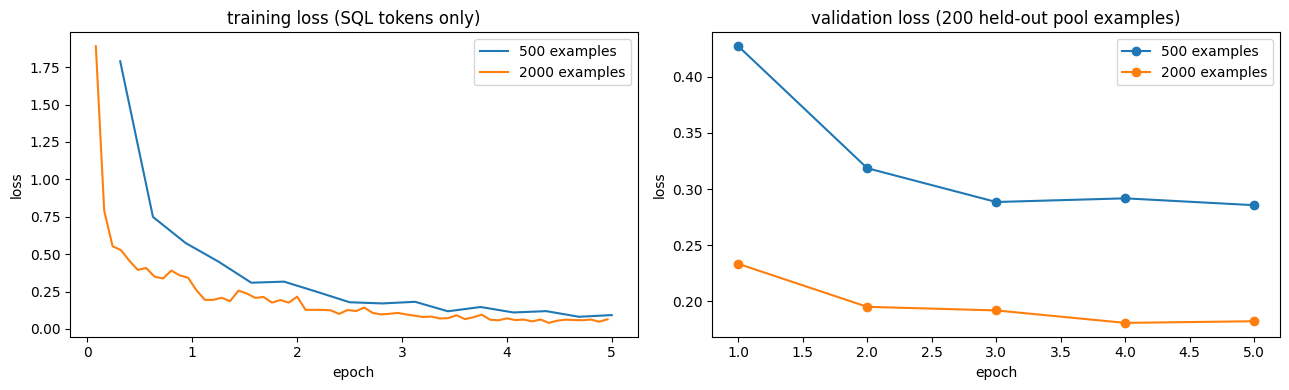

In [22]:
# ---------- Fine-tune twice (500 and 2,000 examples) with identical hyper-parameters ----------
FT_ARGS = dict(num_train_epochs=5, per_device_train_batch_size=16, per_device_eval_batch_size=32,
               learning_rate=1e-4, warmup_steps=20, lr_scheduler_type="cosine", weight_decay=0.0,
               logging_steps=10, eval_strategy="epoch", save_strategy="no", prediction_loss_only=True,
               fp16=(device == "cuda"), report_to="none", seed=SEED)
collator = DataCollatorForSeq2Seq(tok_gpt, padding=True, label_pad_token_id=-100)


def finetune_gpt2(n):
    set_seed(SEED)
    train_tok = FT_DATA[n].map(tokenize_sql, remove_columns=FT_DATA[n].column_names)
    model = AutoModelForCausalLM.from_pretrained(GPT2_NAME).to(device)
    model.config.pad_token_id = tok_gpt.eos_token_id
    trainer = Trainer(model=model, args=TrainingArguments(output_dir=f"./gpt2-sql-{n}", **FT_ARGS),
                      train_dataset=train_tok, eval_dataset=val_tok, data_collator=collator)
    t0 = time.perf_counter()
    trainer.train()
    train_sec = time.perf_counter() - t0
    history = trainer.state.log_history
    del trainer
    clear_gpu()
    return model.eval(), history, train_sec


def run_gpt2(model, desc, batch_size=32):
    prompts = [ft_prompt(c, q) for c, q in zip(sql_test["context"], sql_test["question"])]
    t0 = timer()
    raw = generate_batch(model, tok_gpt, prompts, max_new_tokens=96, batch_size=batch_size, desc=desc)
    sec = (timer() - t0) / len(prompts)
    return [r.split("\n")[0].split("###")[0].strip() for r in raw], sec, raw


FT_MODELS, FT_HISTORY, FT_TRAIN_SEC = {}, {}, {}
for n in FT_SIZES:
    print(f"\n===== Fine-tuning GPT-2 on {n} examples =====")
    FT_MODELS[n], FT_HISTORY[n], FT_TRAIN_SEC[n] = finetune_gpt2(n)
    preds, sec, raw = run_gpt2(FT_MODELS[n], f"GPT-2 FT {n}")
    record_sql(f"GPT-2 fine-tuned ({n} ex.)", preds, sec, raw)
    print(f"training time: {FT_TRAIN_SEC[n]:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in FT_SIZES:
    tr = [h for h in FT_HISTORY[n] if "loss" in h]
    ev = [h for h in FT_HISTORY[n] if "eval_loss" in h]
    axes[0].plot([h["epoch"] for h in tr], [h["loss"] for h in tr], label=f"{n} examples")
    axes[1].plot([h["epoch"] for h in ev], [h["eval_loss"] for h in ev], marker="o", label=f"{n} examples")
axes[0].set_title("training loss (SQL tokens only)"); axes[1].set_title("validation loss (200 held-out pool examples)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
plt.tight_layout(); plt.show()

,system,exact_match,executable,exec_match (heuristic),sec_per_query,labelled examples used,params (M)
0,GPT-2 fine-tuned (2000 ex.),0.565,0.940,0.635,0.026,2000,124.440
1,Qwen-Instruct 3-shot (retrieved demos),0.535,0.915,0.585,0.315,4800,494.033
2,Qwen-Instruct 3-shot (fixed demos),0.465,0.965,0.530,0.315,3,494.033
3,GPT-2 fine-tuned (500 ex.),0.435,0.915,0.490,0.031,500,124.440


Fine-tuning time: {'500 ex.': '42 s', '2000 ex.': '148 s'}


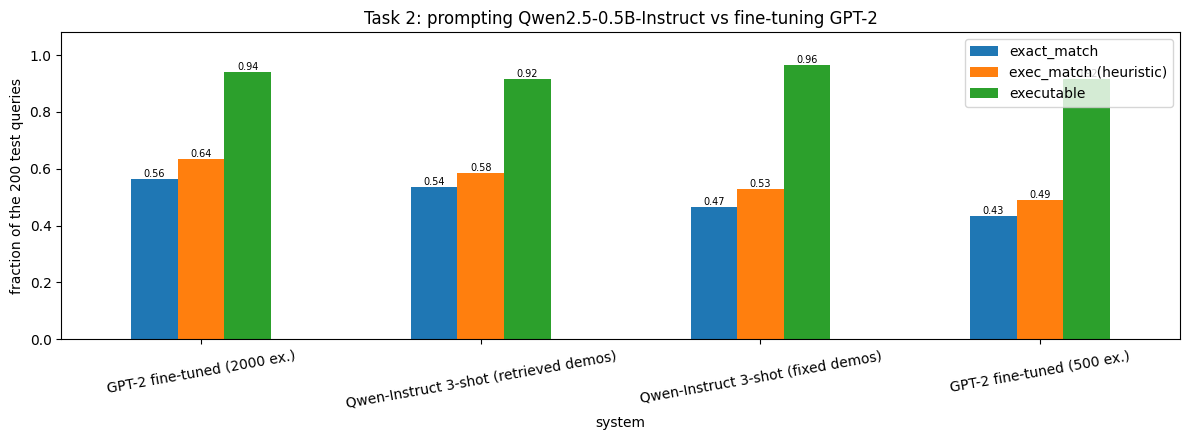

,question,gold,Qwen-Instruct 3-shot (fixed demos),Qwen-Instruct 3-shot (retrieved demos),GPT-2 fine-tuned (500 ex.),GPT-2 fine-tuned (2000 ex.)
0,What is the lowest unlock order for the athens circuit?,"SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""Athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""Athens"""
1,What is the highest pick number of a defensive back with less than 136 overall points?,"SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = ""defensive back""","SELECT MAX(pick__number) FROM table_name_99 WHERE position = ""Defensive Back"" AND overall < 136","SELECT MAX(pick__number) FROM table_name_99 WHERE position = ""defensive back"" AND overall < 136","SELECT MAX(pick__number) FROM table_name_99 WHERE overall = ""133"" AND position = ""defensive back""","SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = ""defensive back"""
2,Which engine has a year larger than 1956?,SELECT engine FROM table_name_74 WHERE year > 1956,SELECT engine FROM table_name_74 WHERE year > 1956,SELECT engine FROM table_name_74 WHERE year > 1956,SELECT engine FROM table_name_74 WHERE year > 1956,SELECT engine FROM table_name_74 WHERE year > 1956
3,"What is the average Attendance, when Venue is ""Candlestick Park"", and when Date is ""December 27""?","SELECT AVG(attendance) FROM table_name_71 WHERE venue = ""candlestick park"" AND date = ""december 27""","SELECT AVG(attendance) FROM table_name_71 WHERE venue = ""Candlestick Park"" AND date = ""December 27""","SELECT AVG(attendance) FROM table_name_71 WHERE venue = ""candlestick park"" AND date = ""december 27""","SELECT AVG(attendance) FROM table_name_71 WHERE venue = ""candlestick park"" AND date = ""december 27""","SELECT AVG(attendance) FROM table_name_71 WHERE venue = ""candlestick park"" AND date = ""december 27"""
4,"What is the Netflix number having a segment D, of NED can corn?","SELECT netflix FROM table_name_2 WHERE segment_d = ""ned can corn""","SELECT netflix FROM table_name_2 WHERE segment_d = ""NED can corn""","SELECT netflix FROM table_name_2 WHERE segment_d = ""NED can corn""","SELECT Netflix FROM table_name_2 WHERE segment_d = ""ned can corn""","SELECT netflix FROM table_name_2 WHERE segment_d = ""ned can corn"""
5,What is the smallest number of fastest laps listed?,SELECT MIN(fastest_laps) FROM table_19312274_3,SELECT MIN(fastest_laps) FROM table_19312274_3,SELECT MIN(fastest_laps) FROM table_19312274_3,"SELECT MIN(fastest_laps) FROM table_19312274_3 WHERE AVG(fastest_laps) = ""1""",SELECT MIN(fastest_laps) FROM table_19312274_3
6,"How many wins have a year after 1976, and 350cc as the class?","SELECT SUM(wins) FROM table_name_21 WHERE year > 1976 AND class = ""350cc""","SELECT SUM(wins) FROM table_name_21 WHERE year > 1976 AND class = ""350cc""","SELECT SUM(wins) FROM table_name_21 WHERE year > 1976 AND class = ""350cc""","SELECT MAX(wins) FROM table_name_21 WHERE year > 1976 AND class = ""50cc""","SELECT SUM(wins) FROM table_name_21 WHERE year > 1976 AND class = ""350cc"""
7,What is the Notes of the Frequency with Format of talk radio?,"SELECT notes FROM table_name_63 WHERE format = ""talk radio""","SELECT notes FROM table_name_63 WHERE format = ""talk radio""","SELECT notes FROM table_name_63 WHERE format = ""talk radio""","SELECT notes FROM table_name_63 WHERE format = ""talk radio""","SELECT notes FROM table_name_63 WHERE format = ""talk radio"""


In [23]:
# ---------- Results ----------
GPT2_PARAMS = sum(p.numel() for p in FT_MODELS[FT_SIZES[0]].parameters())
META_T2 = {"Qwen-Instruct 3-shot (fixed demos)": (N_SHOTS, QWEN_PARAMS),
           "Qwen-Instruct 3-shot (retrieved demos)": (len(sql_cand), QWEN_PARAMS),
           **{f"GPT-2 fine-tuned ({n} ex.)": (n, GPT2_PARAMS) for n in FT_SIZES}}

res_t2 = pd.DataFrame(RESULTS_T2)
res_t2["exec_match (heuristic)"] = [EXTRA_T2.get(s, {}).get("exec_match (heuristic)") for s in res_t2["system"]]
res_t2["sec_per_query"] = [EXTRA_T2.get(s, {}).get("sec_per_query") for s in res_t2["system"]]
res_t2["labelled examples used"] = [META_T2.get(s, (None, None))[0] for s in res_t2["system"]]
res_t2["params (M)"] = [META_T2.get(s, (None, None))[1] / 1e6 if s in META_T2 else None for s in res_t2["system"]]
res_t2 = res_t2.sort_values("exact_match", ascending=False).reset_index(drop=True)
display(res_t2.round(3))
print("Fine-tuning time:", {f"{n} ex.": f"{FT_TRAIN_SEC[n]:.0f} s" for n in FT_SIZES})

metrics = ["exact_match", "exec_match (heuristic)", "executable"]
ax = res_t2.set_index("system")[metrics].plot.bar(figsize=(12, 4.5), rot=10)
ax.set_ylim(0, 1.08); ax.set_ylabel("fraction of the 200 test queries")
ax.set_title("Task 2: prompting Qwen2.5-0.5B-Instruct vs fine-tuning GPT-2")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.show()

# Side-by-side predictions on the first test questions
cmp = pd.DataFrame({"question": list(sql_test["question"]), "gold": list(sql_test["answer"]),
                    **{s: PREDS_T2[s] for s in PREDS_T2}})
display(cmp.head(8))

In [26]:
# ---------- 3. Error analysis: 10 mistakes of the best system ----------
BEST_T2 = max(RESULTS_T2, key=lambda r: r["exact_match"])["system"]
preds = PREDS_T2[BEST_T2]
golds, contexts, questions = list(sql_test["answer"]), list(sql_test["context"]), list(sql_test["question"])
mistakes = [i for i in range(len(preds)) if normalize_sql(preds[i]) != normalize_sql(golds[i])]
print(f"Best system by exact match: {BEST_T2} -> {len(mistakes)} non-exact-match predictions out of {len(preds)}")

sample = sorted(np.random.RandomState(SEED).choice(mistakes, min(10, len(mistakes)), replace=False).tolist())
err_df = pd.DataFrame([{"id": i, "question": questions[i], "schema": contexts[i], "gold": golds[i],
                        "predicted": preds[i], "executes": executes(preds[i], contexts[i]),
                        "suggested label": suggest_error_type(preds[i], golds[i], contexts[i])} for i in sample])

# Every row was read by hand; suggestions that were wrong are overridden here.
# id 78 selects Name from the wrong table (cities instead of counties): a wrong column, not a wrong condition.
MANUAL_LABELS = {78: "wrong column"}
err_df["final label"] = [MANUAL_LABELS.get(i, s) for i, s in zip(err_df["id"], err_df["suggested label"])]
display(err_df)
print("Labels of the 10 mistakes:")
print(err_df["final label"].value_counts().to_string())

all_labels = Counter(suggest_error_type(preds[i], golds[i], contexts[i]) for i in mistakes)
print(f"\nAutomatic (not hand-checked) labels over all {len(mistakes)} mistakes of {BEST_T2}:")
for k, v in all_labels.most_common():
    print(f"   {k:32s} {v:3d}  ({v / len(mistakes):.0%})")

print("\nHow much does exact match underestimate? (heuristic execution match)")
for r in RESULTS_T2:
    xm = EXTRA_T2[r["system"]]["exec_match (heuristic)"]
    print(f"   {r['system']:40s} exact {r['exact_match']:.3f} -> exec_match {xm:.3f}  (+{xm - r['exact_match']:.3f})")

Best system by exact match: GPT-2 fine-tuned (2000 ex.) -> 87 non-exact-match predictions out of 200


,id,question,schema,gold,predicted,executes,suggested label,final label
0,13,What was the attendance at the Meadowlands against the New England Patriots?,"CREATE TABLE table_name_63 (attendance VARCHAR, game_site VARCHAR, opponent VARCHAR)","SELECT attendance FROM table_name_63 WHERE game_site = ""the meadowlands"" AND opponent = ""new england patriots""","SELECT attendance FROM table_name_63 WHERE game_site = ""marshlands"" AND opponent = ""new England pro""",True,wrong value,wrong value
1,37,who else along with scott dixon and graham rahal drove with the most speed,"CREATE TABLE table_13512105_3 (fastest_lap VARCHAR, most_laps_led VARCHAR, pole_position VARCHAR)","SELECT fastest_lap FROM table_13512105_3 WHERE most_laps_led = ""Scott Dixon"" AND pole_position = ""Graham Rahal""","SELECT fastest_lap FROM table_13512105_3 WHERE most_laps_led = ""Scott Dixon and Graham Rahal"" AND pole_position = ""Gordon Ramsay""",True,wrong value,wrong value
2,78,List the names of counties that do not have any cities.,"CREATE TABLE city (Name VARCHAR, County_ID VARCHAR); CREATE TABLE county_public_safety (Name VARCHAR, County_ID VARCHAR)",SELECT Name FROM county_public_safety WHERE NOT County_ID IN (SELECT County_ID FROM city),SELECT Name FROM city WHERE NOT County_ID IN (SELECT County_ID FROM county_public_safety),True,wrong condition or aggregate,wrong column
3,100,what is the least played when points is 36 and place is more than 2?,"CREATE TABLE table_name_39 (played INTEGER, points VARCHAR, place VARCHAR)",SELECT MIN(played) FROM table_name_39 WHERE points = 36 AND place > 2,"SELECT MIN(played) FROM table_name_39 WHERE points = ""36"" AND place > 2",True,correct but written differently,correct but written differently
4,105,"Which Attendance has a First Downs smaller than 26, an Opponent of los angeles rams, and Points For larger than 28?","CREATE TABLE table_name_98 (attendance INTEGER, points_for VARCHAR, first_downs VARCHAR, opponent VARCHAR)","SELECT SUM(attendance) FROM table_name_98 WHERE first_downs < 26 AND opponent = ""los angeles rams"" AND points_for > 28","SELECT AVG(attendance) FROM table_name_98 WHERE first_downs < 26 AND opponent = ""los angeles rams"" AND points_for > 28",True,wrong condition or aggregate,wrong condition or aggregate
5,108,What is the number of total candidates when registered voters is 47742?,"CREATE TABLE table_2676980_4 (total_candidates VARCHAR, registered_voters VARCHAR)",SELECT total_candidates FROM table_2676980_4 WHERE registered_voters = 47742,"SELECT COUNT(total_candidates) FROM table_2676980_4 WHERE registered_voters = ""47742""",True,wrong condition or aggregate,wrong condition or aggregate
6,125,what is the position in round 3?,"CREATE TABLE table_name_9 (position VARCHAR, round VARCHAR)",SELECT position FROM table_name_9 WHERE round = 3,"SELECT position FROM table_name_9 WHERE round = ""3""",True,correct but written differently,correct but written differently
7,162,List every album's title.,CREATE TABLE albums (title VARCHAR),SELECT title FROM albums,SELECT title FROM albums ORDER BY title DESC,True,correct but written differently,correct but written differently
8,178,"What's the highest lowest number of capacity that ibrox stadium has when the average is larger than 49,143?","CREATE TABLE table_name_67 (lowest INTEGER, stadium VARCHAR, average VARCHAR)","SELECT MAX(lowest) FROM table_name_67 WHERE stadium = ""ibrox stadium"" AND average > 49 OFFSET 143","SELECT MAX(lowest) FROM table_name_67 WHERE stadium = ""ibrox"" AND average > 49 OFFSET 0007",False,invalid SQL,invalid SQL
9,199,What is the Trofeo Fast Team with a point classification of Silvio Martinello and stage 6?,"CREATE TABLE table_name_67 (trofeo_fast_team VARCHAR, points_classification VARCHAR, stage VARCHAR)","SELECT trofeo_fast_team FROM table_name_67 WHERE points_classification = ""silvio martinello"" AND stage = ""6""","SELECT trofeo_fast_team FROM table_name_67 WHERE points_classification = ""silvio martinello"" AND stage = 6"

Labels of the 10 mistakes:
final label
correct but written differently    4
wrong value                        2
wrong condition or aggregate       2
wrong column                       1
invalid SQL                        1

Automatic (not hand-checked) labels over all 87 mistakes of GPT-2 fine-tuned (2000 ex.):
   wrong value                       37  (43%)
   wrong condition or aggregate      21  (24%)
   correct but written differently   14  (16%)
   invalid SQL                       12  (14%)
   wrong column                       3  (3%)

How much does exact match underestimate? (heuristic execution match)
   Qwen-Instruct 3-shot (fixed demos)       exact 0.465 -> exec_match 0.530  (+0.065)
   Qwen-Instruct 3-shot (retrieved demos)   exact 0.535 -> exec_match 0.585  (+0.050)
   GPT-2 fine-tuned (500 ex.)               exact 0.435 -> exec_match 0.490  (+0.055)
   GPT-2 fine-tuned (2000 ex.)              exact 0.565 -> exec_match 0.635  (+0.070)


In [25]:
print("Task 2 settings:")
for k, v in {"prompting model": f"{QWEN_INSTRUCT} (fp32, chat template, greedy, max 128 new tokens)",
             "demonstrations": f"{N_SHOTS} (fixed: lookup / COUNT / aggregate; extra run: TF-IDF retrieved)",
             "fine-tuned model": f"{GPT2_NAME} (loss on SQL tokens + end-of-text only)",
             "training sizes": FT_SIZES, "max training length (tokens)": MAX_LEN,
             "hyper-parameters": FT_ARGS, "seed": SEED,
             "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}.items():
    print(f"  {k:30s}: {v}")

Task 2 settings:
  prompting model               : Qwen/Qwen2.5-0.5B-Instruct (fp32, chat template, greedy, max 128 new tokens)
  demonstrations                : 3 (fixed: lookup / COUNT / aggregate; extra run: TF-IDF retrieved)
  fine-tuned model              : openai-community/gpt2 (loss on SQL tokens + end-of-text only)
  training sizes                : [500, 2000]
  max training length (tokens)  : 256
  hyper-parameters              : {'num_train_epochs': 5, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 32, 'learning_rate': 0.0001, 'warmup_steps': 20, 'lr_scheduler_type': 'cosine', 'weight_decay': 0.0, 'logging_steps': 10, 'eval_strategy': 'epoch', 'save_strategy': 'no', 'prediction_loss_only': True, 'fp16': True, 'report_to': 'none', 'seed': 0}
  seed                          : 0
  hardware                      : Tesla T4


### Task 2: Results and analysis ✍️

The settings are printed above. Qwen2.5-0.5B-Instruct was prompted through its chat template with 3 demos and greedy decoding. GPT-2 was trained for 5 epochs with batch size 16, learning rate 1e-4, a cosine schedule and fp16. I used seed 0 and a T4 GPU for everything.

| System (sql_test, 200 queries) | Exact match | Executable | Exec-match (heuristic) | sec / query | Labelled data |
|---|---|---|---|---|---|
| Qwen-Instruct 3-shot (fixed demos) | 0.465 | 0.965 | 0.530 | 0.315 | 3 |
| Qwen-Instruct 3-shot (retrieved demos) | 0.535 | 0.915 | 0.585 | 0.315 | 4,800-example pool |
| GPT-2 fine-tuned (500 ex.) | 0.435 | 0.915 | 0.490 | 0.031 | 500 |
| GPT-2 fine-tuned (2,000 ex.) | 0.565 | 0.940 | 0.635 | 0.026 | 2,000 |

Training took 42 s with 500 examples and 148 s with 2,000. The final validation loss was 0.286 and 0.181 respectively.

**10 mistakes of GPT-2 (2,000 ex.)**

I went through each one by hand. The automatic label was right for 9 of them; I changed id 78 to "wrong column".

| # | id | Label | What happened |
|---|---|---|---|
| 1 | 13 | wrong value | made up "marshlands" and "new England pro" instead of copying the names from the question |
| 2 | 37 | wrong value | put both drivers into one condition and invented "Gordon Ramsay" |
| 3 | 78 | wrong column | took Name from the city table instead of the county table, so it lists cities |
| 4 | 100 | correct but written differently | `points = "36"` vs `points = 36`; points is a text column, so both return the same rows |
| 5 | 105 | wrong condition or aggregate | AVG instead of SUM, though the question doesn't really say which |
| 6 | 108 | wrong condition or aggregate | used COUNT because the question says "number of" |
| 7 | 125 | correct but written differently | `round = "3"` vs `round = 3`, same result on a text column |
| 8 | 162 | correct but written differently | added ORDER BY title DESC: same rows, just sorted |
| 9 | 178 | invalid SQL | OFFSET without LIMIT; the gold query is broken here too (it turned "49,143" into OFFSET 143) |
| 10 | 199 | correct but written differently | `stage = 6` vs `stage = "6"` |

So: 4 written differently, 2 wrong value, 2 wrong condition/aggregate, 1 wrong column, 1 invalid SQL.

**(a)** GPT-2 trained on 2,000 examples did best overall, with 0.565 exact match against 0.465 for Qwen with 3 examples. It even beat Qwen with retrieved examples (0.535), while being 4 times smaller and about 12 times faster per query. With only 500 examples, though, it was slightly worse than prompting (0.435). So going from 500 to 2,000 examples is what made the difference: 13 points. The 500 run had stopped improving by epoch 3, so it needed more data, not more training.

**(b)** 4 of the 10 were actually correct. Three only differ in whether a number has quotes around it, and one just adds an ORDER BY. Over the whole test set, the execution check says 14 of the 87 mistakes are really correct (0.565 goes up to 0.635). Exact match compares the text of the query, not what it returns, and the same query can be written in many ways. The gold answers are also a bit noisy: 2.5% of them don't even run.

**(c)** I'd recommend fine-tuning, but starting with prompting. The fine-tuned model was the most accurate, and it's small and cheap to run. The catch is that it needs around 2,000 labelled examples; with 500 it lost to plain prompting. So I would launch with the prompted model, keep the queries analysts check and fix, and fine-tune once there are about 2,000. New tables aren't a big problem for either system, because the schema is part of the input. Retraining would only be needed for new kinds of queries, like joins.